# JOJA: Analyse exploratoire des données

## Contexte et objectif

Nous disposons des données d'un site de livraison de courses : **~3,4 millions de commandes** passées par **~206 000 clients**, chaque client ayant entre 4 et 100 commandes. Les produits sont regroupés en **rayons** (*aisles*), eux-mêmes regroupés en **départements**.

Objectif : explorer ces données pour en tirer des **insights actionnables**, c'est-à-dire des constats chiffrés qui débouchent sur une décision concrète pouvant améliorer l'activité du e-commerce.

## Les fichiers .csv téléchargés

| Fichier | Une ligne = | Colonnes clés |
|---|---|---|
| `orders` | une commande | `order_id`, `user_id`, `order_number` (rang de la commande du client), `order_dow` (jour, 0 = dimanche), `order_hour_of_day` (heure), `days_since_prior_order` |
| `order_products` | un produit dans une commande | `order_id`, `product_id`, `add_to_cart_order` (position dans le panier), `reordered` (1 = déjà commandé avant) |
| `products` | un produit | `product_id`, `product_name`, `aisle_id`, `department_id` |
| `aisles` | un rayon | `aisle_id`, `aisle` |
| `departments` | un département | `department_id`, `department` |


## Méthodologie

Pour comprendre ces données, nous utilisons la méthode EDA (exploratory data analysis). D'après nos recherches, cette méthode consiste à "transformer un dataset brut en un objet compréhensible. Elle permet de révéler des structures invisibles, d’identifier des biais et d’orienter les choix méthodologiques pour les analyses futures" ([iana-data](https://www.iana-data.org/articles/analyse-exploratoire-des-donnees-eda/#definition)) :

1. **Chargement et typage** (lire les fichiers, choisir des types adaptés au volume)
2. **Contrôle qualité** (dimensions, valeurs manquantes, valeurs aberrantes)
3. **Préparation** (merge/réorganiser les données qui vont ensemble)
4. **Analyse question par question** : problème → mesure → **un** graphique adapté → observation → piste d'action.
5. **Synthèse** 

## Outils et justification des choix

| Paquet | Rôle | Pourquoi ce choix |
|---|---|---|
| **pandas** | manipulation de données tabulaires | structure `DataFrame` ; gère nos volumes (32 M lignes) en mémoire vive |
| **numpy** | calcul numérique vectorisé | opérations sur des tableaux entiers sans boucle Python |
| **matplotlib** | graphiques | bibliothèque de référence pour personnaliser les éléments d'un graphique (axes, titres, légendes) |
| **seaborn** | graphiques statistiques | introduite à partir des questions qui en ont besoin |

## Règle sur les visualisations

Nous n'utilisons pas le même graphique pour des besoins différents :

| Besoin | Graphique retenu |
|---|---|
| **distribution** (répartition d'une variable) | histogramme, boîte à moustaches |
| **comparaison** (classer des catégories) | diagramme en barres |
| **proportion** (part d'un tout) | barres empilées à 100 % |
| **relation** (lien entre deux variables) | nuage de points, carte de chaleur |


# 1. Préparation des données

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA = Path("datasets")

pd.set_option("display.max_columns", None)   
sns.set_theme(style="whitegrid")           

print("pandas", pd.__version__)

pandas 3.0.5


## 1.1 Chargement et typage

`order_products.csv` fait **32 millions de lignes**. Si on laisse pandas deviner les types, il met des `int64`
partout (8 octets par nombre) et le texte en `object` : on gaspille ~3× la mémoire nécessaire.

La bonne pratique : **imposer le type de chaque colonne à la lecture** avec `dtype=`.

Règles utilisées ici :
- `int8` : entiers de −128 à 127 → `order_dow` (0–6), `department_id` (1–21), `reordered` (0/1)
- `int16` : jusqu'à ~32 000 → `order_number`, `add_to_cart_order`, `aisle_id`
- `int32` : jusqu'à ~2 milliards → tous les `*_id` volumineux (`order_id`, `user_id`, `product_id`)
- `float32` : `days_since_prior_order` (a des valeurs manquantes → doit être un float)
- `category` : `eval_set` (seulement 3 valeurs distinctes répétées 3,4 M de fois)
- `string` : les libellés texte

Note : `order_hour_of_day` est écrit `"08"` dans le fichier ; demander `int8` suffit, pandas convertit `"08" → 8`.

### 1.1.1 Les 3 dictionnaires (petits fichiers)

In [2]:
aisles = pd.read_csv(DATA / "aisles.csv", dtype={
    "aisle_id": "int16",
    "aisle": "string",
})

departments = pd.read_csv(DATA / "departments.csv", dtype={
    "department_id": "int8",
    "department": "string",
})

products = pd.read_csv(DATA / "products.csv", dtype={
    "product_id": "int32",
    "product_name": "string",
    "aisle_id": "int16",
    "department_id": "int8",
})

print("aisles     ", aisles.shape)
print("departments", departments.shape)
print("products   ", products.shape)
products.head()

aisles      (134, 2)
departments (21, 2)
products    (49688, 4)


,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


### 1.1.2 Les commandes (`orders`)

In [3]:
orders = pd.read_csv(DATA / "orders.csv", dtype={
    "order_id": "int32",
    "user_id": "int32",
    "eval_set": "category",
    "order_number": "int16",
    "order_dow": "int8",
    "order_hour_of_day": "int8",
    "days_since_prior_order": "float32",
})

print(orders.shape)
print(orders["eval_set"].value_counts())
orders.head()

(3421083, 7)
eval_set
prior    3214874
train     131209
test       75000
Name: count, dtype: int64


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0


### 1.1.3 Le contenu des paniers (`order_products`)

Le gros fichier. Avec les `dtype` ci-dessous : 4 + 4 + 2 + 1 = **11 octets/ligne** → ~350 Mo en RAM.
Sans typage, ce serait ~1 Go. Le chargement peut quelques dizaines de secondes.

In [4]:
order_products = pd.read_csv(DATA / "order_products.csv", dtype={
    "order_id": "int32",
    "product_id": "int32",
    "add_to_cart_order": "int16",
    "reordered": "int8",
})

print(order_products.shape)
order_products.head()

(32434489, 4)


,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0
3,2,45918,4,1
4,2,30035,5,0


### 1.1.4 Vérification de l'empreinte mémoire

In [5]:
for nom, df in [("aisles", aisles), ("departments", departments), ("products", products),
                ("orders", orders), ("order_products", order_products)]:
    mo = df.memory_usage(deep=True).sum() / 1e6
    print(f"{nom:16} {df.shape[0]:>10,} lignes   {mo:8.1f} Mo")

aisles                  134 lignes        0.0 Mo
departments              21 lignes        0.0 Mo
products             49,688 lignes        2.3 Mo
orders            3,421,083 lignes       58.2 Mo
order_products   32,434,489 lignes      356.8 Mo


## 1.2 Contrôle qualité

Avant de répondre à une seule question, on vérifie que les données se comportent comme on l'imagine. Trois
familles de vérifications :

1. **Valeurs manquantes** : où, combien, est-ce logique ?
2. **Doublons** : une clé censée être unique (`order_id`, `product_id`) l'est-elle vraiment ?
3. **Cohérence entre tables** : est-ce que les jointures qu'on prévoit de faire vont bien matcher ?

C'est l'étape qu'on est tenté de sauter — et où se cachent les surprises qui faussent tout le reste.

### 1.2.1 Valeurs manquantes

In [6]:
for nom, df in [("aisles", aisles), ("departments", departments), ("products", products),
                ("orders", orders), ("order_products", order_products)]:
    na = df.isna().sum()
    na = na[na > 0]
    print(f"--- {nom} ---")
    print(na if len(na) else "aucune valeur manquante")
    print()

--- aisles ---
aucune valeur manquante

--- departments ---
aucune valeur manquante

--- products ---
aucune valeur manquante

--- orders ---
days_since_prior_order    206209
dtype: int64



--- order_products ---
aucune valeur manquante



Seule `orders.days_since_prior_order` a des manquants : **206 209**. C'est exactement le nombre de clients
distincts (`user_id`). L'hypothèse à vérifier : ce sont les 1ʳᵉˢ commandes de chaque client (`order_number == 1`),
pour lesquelles il n'existe pas de "commande précédente" — donc le NaN est **normal**, pas une erreur de saisie.

In [ ]:
print("n° de clients distincts       :", orders["user_id"].nunique())
print("lignes avec délai manquant    :", orders["days_since_prior_order"].isna().sum())
print("1res commandes (order_number==1):", (orders["order_number"] == 1).sum())

# vérification : le manquant coïncide-t-il avec order_number == 1 ?
premiere_commande = orders["order_number"] == 1
delai_manquant = orders["days_since_prior_order"].isna()
print("coïncidence parfaite :", (premiere_commande == delai_manquant).all())

n° de clients distincts       : 206209
lignes avec délai manquant    : 206209
1res commandes (order_number==1): 206209


coïncidence parfaite : True


### 1.2.2 Doublons sur les clés d'identité

`order_id` doit être unique dans `orders`, `product_id` unique dans `products`. On vérifie.

In [8]:
print("order_id dupliqués dans orders     :", orders["order_id"].duplicated().sum())
print("product_id dupliqués dans products :", products["product_id"].duplicated().sum())
print("aisle_id dupliqués dans aisles     :", aisles["aisle_id"].duplicated().sum())
print("department_id dupliqués            :", departments["department_id"].duplicated().sum())

order_id dupliqués dans orders     : 0
product_id dupliqués dans products : 0
aisle_id dupliqués dans aisles     : 0
department_id dupliqués            : 0


### 1.2.3 Cohérence entre `orders` et `order_products` — le point le plus important de cette section

Jusqu'ici je t'ai dit qu'`eval_set` valait `prior` / `train` / `test`, et que `test` n'avait pas de contenu de
panier. Vérifions ce qu'il en est **réellement** pour `train` aussi, au lieu de le supposer : quels `eval_set`
sont effectivement présents dans `order_products` ?

In [9]:
ids_avec_panier = order_products["order_id"].unique()
print("order_id distincts dans order_products :", len(ids_avec_panier))

couverture = orders.loc[orders["order_id"].isin(ids_avec_panier), "eval_set"].value_counts()
print("\nÀ quel eval_set appartiennent ces commandes ?")
print(couverture)

order_id distincts dans order_products :

 3214874

À quel eval_set appartiennent ces commandes ?
eval_set
prior    3214874
test           0
train          0
Name: count, dtype: int64


**Résultat (à confirmer en exécutant la cellule ci-dessus) : `order_products` ne couvre QUE les commandes
`prior`** (3 214 874)  ni `train`, ni évidemment `test`.

Conséquence concrète pour la suite :
- **Q1, Q3, Q5** (qui ont besoin du contenu des paniers) porteront uniquement sur les commandes `prior`.
- **Q2, Q4** (qui ne dépendent que de `orders` : jour/heure, délais) peuvent utiliser tout `orders` sans problème
  puisqu'elles n'ont pas besoin de `order_products`.

## 1.3 Choisir le périmètre d'analyse

On l'a découvert en 1.2 : `order_products` ne contient le détail que des commandes
`prior`. Les 206 209 commandes `train` + `test` (la dernière de chaque client) sont
dans `orders` mais **sans aucun produit**.

Si on analyse le **contenu** des paniers, ces commandes ne servent à rien (elles
sont vides). Si on analyse seulement `orders` (heures, jours...), on pourrait les
garder, mais on mélangerait alors deux périmètres différents selon les questions.
Pour rester cohérent, on se restreint au
périmètre `prior`.


In [10]:
commandes = orders[orders["eval_set"] == "prior"].copy()
print("Commandes retenues pour l'analyse :", f"{len(commandes):,}")

hist = commandes.groupby("user_id")["order_id"].count()
print("Historique par client (prior) : de", hist.min(), "a", hist.max(), "commandes")


Commandes retenues pour l'analyse : 3,214,874
Historique par client (prior) : de 3 a 99 commandes


En retirant la dernière commande de chaque client, l'historique descend à un minimum
de **3 commandes** pour certains clients (au lieu de 4).

## 1.4 Une table produits complète

Plusieurs questions auront besoin du **rayon** (`aisle`) et du **département**
(`department`) de chaque produit. Plutôt que de refaire la jointure à chaque fois,
on construit une fois pour toutes une table `produits` enrichie, en rattachant
`aisles` et `departments` par leur identifiant (`merge` en chaîne).


In [11]:
produits = (
    products
    .merge(aisles, on="aisle_id")
    .merge(departments, on="department_id")
)
produits.head()


,product_id,product_name,aisle_id,department_id,aisle,department
0,1,Chocolate Sandwich Cookies,61,19,cookies cakes,snacks
1,2,All-Seasons Salt,104,13,spices seasonings,pantry
2,3,Robust Golden Unsweetened Oolong Tea,94,7,tea,beverages
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1,frozen meals,frozen
4,5,Green Chile Anytime Sauce,5,13,marinades meat preparation,pantry


`produits` porte maintenant, à côté de chaque `product_id` : le nom du produit,
celui de son rayon et celui de son département.

À partir d'ici, on travaille avec :

- **`commandes`** : les ~3,2 M commandes `prior` ;
- **`order_products`** : leur détail (un produit par ligne) ;
- **`produits`** : le référentiel produit enrichi.


---
# Analyse des performances du e-commerce

## *Question 1 : Quels sont les produits les plus vendus ?*

**Type de question :** on veut **classer** des catégories (les produits) du plus vendu au moins vendu. Selon les règles de visualisation, il s'agit d'une une **comparaison**, donc on utilise un graphique en **barres**. Comme les noms de produits sont longs et nombreux, on prend le **top 15** en **barres horizontales**.

« Le plus vendu » = le produit qui apparaît dans le plus grand nombre de lignes de `order_products`.

Sachant qu'une une ligne de `order_products` = un produit acheté dans une commande, on compte les lignes par `product_id`.

In [12]:

ventes_par_produit = order_products.groupby("product_id").size()
ventes_par_produit.head()

product_id
1    1852
2      90
3     277
4     329
5      15
dtype: int64

`.size()` renvoie une **Series** : index = `product_id`, valeur = nombre de ventes.
On veut les plus gros :

- `.sort_values(ascending=False)` : de la plus grande valeur à la plus petite
- `.head(15)` : on garde les 15 premières


In [13]:
top15 = ventes_par_produit.sort_values(ascending=False).head(15)
top15


product_id
24852    472565
13176    379450
21137    264683
21903    241921
47209    213584
47766    176815
47626    152657
16797    142951
26209    140627
27845    137905
27966    137057
22935    113426
24964    109778
45007    104823
39275    100060
dtype: int64

On a des `product_id` (des numéros), pas des noms. Deux étapes :

- `.reset_index(name="ventes")` : transforme la Series en **tableau** à 2 colonnes
  (`product_id`, `ventes`).
- `.merge(products[["product_id", "product_name"]], on="product_id")` : rapproche
  de `products` pour récupérer `product_name` à partir du `product_id`.

In [14]:
top15_noms = (
    top15
    .reset_index(name="ventes")                         
    .merge(products[["product_id", "product_name"]], on="product_id")
)
top15_noms


,product_id,ventes,product_name
0,24852,472565,Banana
1,13176,379450,Bag of Organic Bananas
2,21137,264683,Organic Strawberries
3,21903,241921,Organic Baby Spinach
4,47209,213584,Organic Hass Avocado
5,47766,176815,Organic Avocado
6,47626,152657,Large Lemon
7,16797,142951,Strawberries
8,26209,140627,Limes
9,27845,137905,Organic Whole Milk


**Le graphique.** `plt.barh(noms, valeurs)` = barres **horizontales** (pratique
quand les libellés sont longs). Pour que le produit n°1 apparaisse tout en haut, on trie le tableau en ordre **croissant**.


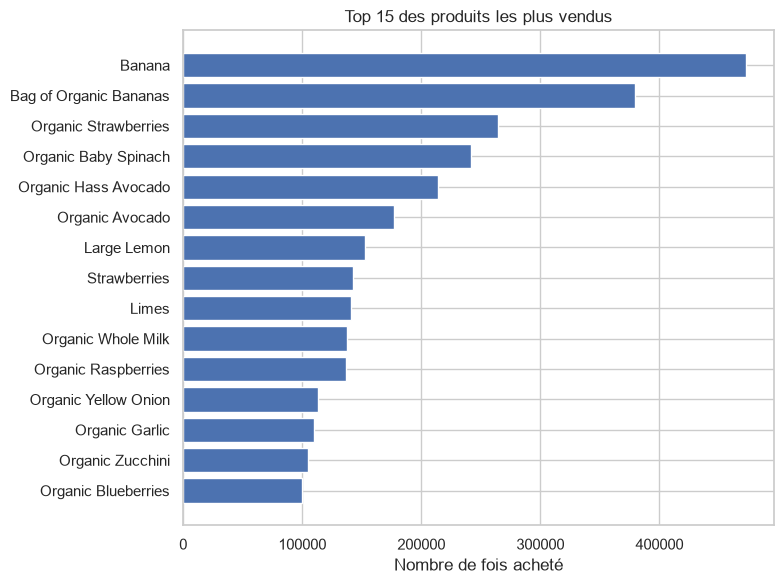

In [15]:
graph = top15_noms.sort_values("ventes") 

plt.figure(figsize=(8, 6))
plt.barh(graph["product_name"], graph["ventes"])
plt.xlabel("Nombre de fois acheté")
plt.title("Top 15 des produits les plus vendus")
plt.tight_layout()
plt.show()


**Observations :**

- Le classement est dominé par des **fruits et légumes frais**, très souvent bio :
  bananes, fraises, épinards, avocats, myrtilles... (mention *Organic* récurrente).
- Le produit n°1 (*Banana*) pèse à lui seul ~1,46 % de toutes les lignes vendues du site
- Ce sont des produits **peu chers achetés très fréquemment** (la fréquence d'achat)

**Piste business :**

Veiller au réapprovisionnement ininterrompu de ces 15 produits et les mettre en tête de parcours ou dans les suggestions par défaut pour accélérer le remplissage du panier.

## *Question 2 : Quel est le ratio de commandes bio vs non-bio ?*

**Type de question :** on veut une **part d'un tout** (les commandes qui contiennent
du bio, rapportées à l'ensemble des commandes). D'après les règles de visualisation,
une proportion se montre avec une **barre empilée à 100 %**.

**« Commande bio »** = une commande qui contient **au moins un** produit bio. Le
seul indice pour repérer un produit bio est son **nom** : on considère bio tout
produit dont le `product_name` contient « organic ». C'est une approximation (un
produit bio mal nommé passera pour non-bio), mais c'est la seule information
disponible.


In [16]:
produits["bio"] = produits["product_name"].str.contains("organic", case=False, na=False)

nb_bio = produits["bio"].sum()
print(f"Produits bio : {nb_bio:,} / {len(produits):,} ({nb_bio / len(produits):.1%} du catalogue)")
produits.loc[produits["bio"], ["product_name", "aisle", "department"]].head()


Produits bio : 5,036 / 49,688 (10.1% du catalogue)


,product_name,aisle,department
22,Organic Turkey Burgers,packaged poultry,meat seafood
32,Organic Spaghetti Style Pasta,dry pasta,dry goods pasta
40,Organic Sourdough Einkorn Crackers Rosemary,crackers,snacks
42,Organic Clementines,packaged vegetables fruits,produce
46,Onion Flavor Organic Roasted Seaweed Snack,asian foods,international


`str.contains("organic", case=False)` teste, pour chaque nom de produit, la présence
du mot « organic » sans tenir compte de la casse ; `na=False` traite un nom manquant
comme « pas bio ».

Environ **10 % du catalogue** est bio. On reporte maintenant cette étiquette sur
chaque ligne de `order_products` (une ligne = un produit dans une commande). Plutôt
qu'un `merge` sur 32 M de lignes, on construit l'ensemble des `product_id` bio et on
teste l'appartenance avec `.isin()`.


In [17]:
bio_ids = set(produits.loc[produits["bio"], "product_id"])
order_products["bio"] = order_products["product_id"].isin(bio_ids)

part_lignes_bio = order_products["bio"].mean()
print(f"Lignes produits bio : {part_lignes_bio:.1%}")

Lignes produits bio : 31.6%


**31,6 %** des lignes achetées sont des produits bio : trois fois plus que la part
du bio dans le catalogue (10 %). Les produits bio se vendent donc proportionnellement
bien mieux que les autres.

On passe au niveau **commande**. Une commande est « bio » si **au moins un** de ses
produits l'est. `groupby("order_id")["bio"].agg(["any", "all"])` calcule en un seul
passage, pour chaque commande : `any` = contient-elle au moins un produit bio,
`all` = sont-ils **tous** bio.


In [18]:
agg = order_products.groupby("order_id")["bio"].agg(["any", "all"])

part_commandes_bio     = agg["any"].mean()
part_commandes_100_bio = agg["all"].mean()
print(f"Commandes avec au moins un produit bio : {part_commandes_bio:.1%}")
print(f"Commandes sans aucun produit bio       : {1 - part_commandes_bio:.1%}")
print(f"Commandes 100 % bio                    : {part_commandes_100_bio:.1%}")

Commandes avec au moins un produit bio : 73.6%
Commandes sans aucun produit bio       : 26.4%
Commandes 100 % bio                    : 2.5%


**73,6 % des commandes** contiennent au moins un produit bio, contre 26,4 % sans
aucun. Le bio n'est pas un segment de niche sur ce site : la majorité des paniers
sont concernés.

On visualise les deux niveaux de lecture (commande / ligne produit) l'un sous
l'autre, chacun en barre empilée à 100 %.


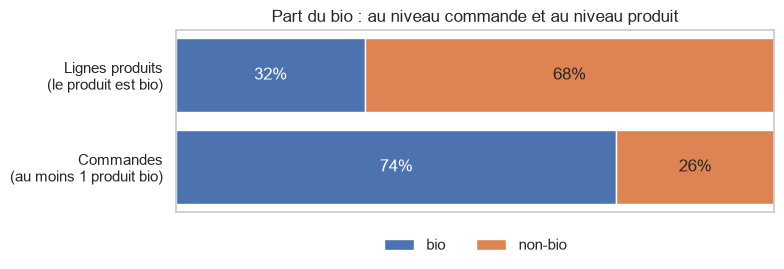

In [19]:
niveaux      = ["Commandes\n(au moins 1 produit bio)", "Lignes produits\n(le produit est bio)"]
part_bio     = [part_commandes_bio, part_lignes_bio]
part_non_bio = [1 - p for p in part_bio]

plt.figure(figsize=(8, 3))
plt.barh(niveaux, part_bio, label="bio")
plt.barh(niveaux, part_non_bio, left=part_bio, label="non-bio")

for i, p in enumerate(part_bio):
    plt.text(p / 2,           i, f"{p:.0%}",     va="center", ha="center", color="white")
    plt.text(p + (1 - p) / 2, i, f"{1 - p:.0%}", va="center", ha="center")

plt.xlim(0, 1)
plt.xticks([])
plt.title("Part du bio : au niveau commande et au niveau produit")
plt.legend(loc="lower center", bbox_to_anchor=(0.5, -0.3), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

**Observations :**

- **73,6 % des commandes** contiennent du bio, mais seulement **31,6 % des lignes
  produits** le sont : dans une commande « bio » typique, le bio cohabite avec une
  majorité de produits non-bio.
- Le bio est **sur-représenté dans les ventes** par rapport à l'offre : 10 % du
  catalogue, 32 % des achats. Ce sont surtout les gros volumes du top 15 (bananes,
  épinards, fraises… en version bio) qui tirent ce chiffre.
- Les commandes **100 % bio** sont rares (~2,5 %) : le bio est un complément de
  panier.

**Piste business :**

Le bio est un réflexe d'achat de masse, pas une niche. Sur les 26 % de commandes
sans aucun produit bio, proposer l'équivalent bio d'un produit déjà au panier au
moment de l'ajout pour convertir ces paniers.


## *Question 3 : Quel est le taux de réachat, au global et par département ?*

**Mesure.** La colonne `reordered` vaut 1 si le client avait déjà commandé ce
produit auparavant, 0 sinon. Le taux de réachat d'un ensemble de lignes est la
moyenne de `reordered` sur ces lignes.

**Visualisation.** On compare des catégories (les départements) sur un même
indicateur : c'est une comparaison, donc un diagramme en barres. Le taux global sert
de repère.


In [20]:
print(f"Taux de reachat global : {order_products['reordered'].mean():.1%}")


Taux de reachat global : 59.0%


59 % des produits achetés avaient déjà été commandés par le client. On décompose par
département : on rattache chaque ligne à son `department_id` via `produits`, puis on
calcule la moyenne de `reordered` par département. On garde aussi le nombre de lignes
pour situer le poids de chaque département.


In [21]:
dept_par_produit = produits.set_index("product_id")["department_id"]
order_products["department_id"] = order_products["product_id"].map(dept_par_produit).astype("int16")

reachat_dept = (
    order_products.groupby("department_id")["reordered"].agg(taux="mean", lignes="size")
    .join(departments.set_index("department_id")["department"])
    .sort_values("taux")
)
reachat_dept


,taux,lignes,department
department_id,,,
11,0.321129,447123,personal care
13,0.346721,1875577,pantry
6,0.369229,269253,international
21,0.395849,69145,missing
17,0.402178,738666,household
2,0.407980,36291,other
15,0.457405,1068058,canned goods
9,0.461076,866627,dry goods pasta
1,0.541885,2236432,frozen


On trace les départements du taux le plus faible au plus fort, avec une ligne
verticale au taux global.


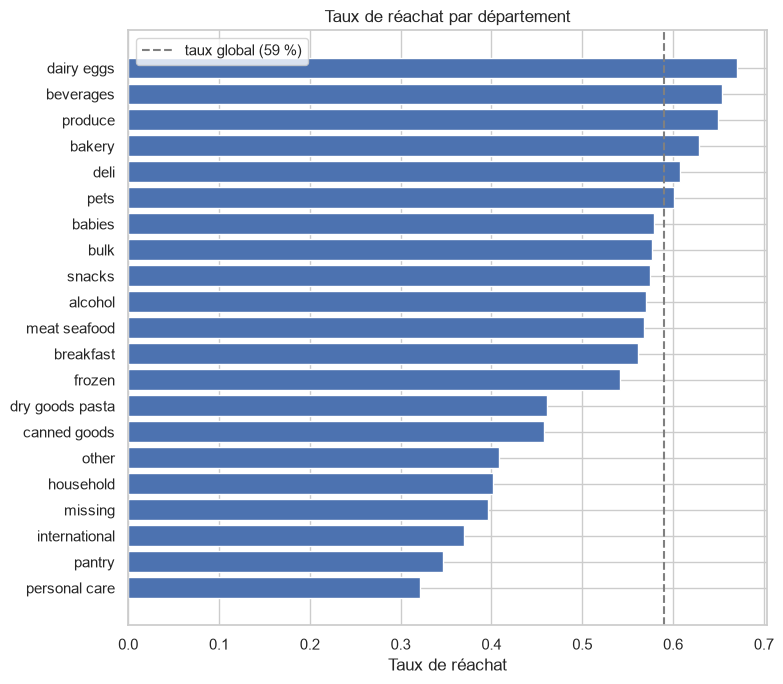

In [22]:
plt.figure(figsize=(8, 7))
plt.barh(reachat_dept["department"], reachat_dept["taux"])
plt.axvline(order_products["reordered"].mean(), color="grey", linestyle="--",
            label="taux global (59 %)")
plt.xlabel("Taux de réachat")
plt.title("Taux de réachat par département")
plt.legend()
plt.tight_layout()
plt.show()


**Observations :**

- Le taux de réachat va de **32 % (personal care)** à **67 % (dairy eggs)**.
- Au-dessus de la moyenne : des consommables du quotidien (dairy eggs, beverages,
  produce, bakery, deli), qui s'épuisent vite et se rachètent.
- En dessous : des achats ponctuels ou de stock (personal care, pantry, household,
  international, canned goods).
- Les deux plus gros départements en volume (produce 9,5 M lignes, dairy eggs
  5,4 M) sont aussi parmi les plus fidélisants : le cœur du chiffre d'affaires est
  récurrent.

**Piste business :**

Cibler les départements à fort volume mais faible réachat (pantry, canned goods,
frozen) avec des rappels de réassort ou des abonnements : produits que le client
rachètera mais oublie. Sur les départements à fort réachat, la priorité est la
disponibilité, pas la promotion.


## *Question 4 : Quelle est la concentration des ventes ?*

**Mesure.** On classe les produits du plus vendu au moins vendu (nombre de lignes
dans `order_products`), puis on cumule leur part du volume total. On cherche combien
de produits suffisent pour représenter 80 % des ventes.

**Visualisation.** On trace la **courbe de concentration** : en abscisse la part
cumulée des produits, en ordonnée la part cumulée du volume. Ce n'est ni une
distribution ni une comparaison de catégories : c'est une courbe cumulée, qui se lit
par rapport à la diagonale « répartition uniforme ».


In [23]:
ventes = order_products.groupby("product_id").size().sort_values(ascending=False)

cumul_volume   = ventes.cumsum() / ventes.sum()
cumul_produits = pd.Series(range(1, len(ventes) + 1)) / len(ventes)

n_catalogue = products["product_id"].nunique()
k80 = int((cumul_volume < 0.8).sum()) + 1

print(f"{k80:,} produits realisent 80 % du volume "
      f"({k80 / len(ventes):.1%} des produits vendus, {k80 / n_catalogue:.1%} du catalogue)")
print(f"Le 1 % de produits le plus vendu    : {cumul_volume.iloc[int(0.01 * len(ventes))]:.0%} du volume")
print(f"Produits vendus une seule fois : {(ventes == 1).sum()}  |  jamais vendus : {n_catalogue - len(ventes)}")


4,538 produits realisent 80 % du volume (9.1% des produits vendus, 9.1% du catalogue)
Le 1 % de produits le plus vendu    : 43% du volume
Produits vendus une seule fois : 131  |  jamais vendus : 11


Environ **4 500 produits** (9 % du catalogue) réalisent 80 % du volume, et le 1 % de
tête (~500 produits) en concentre déjà ~43 %.


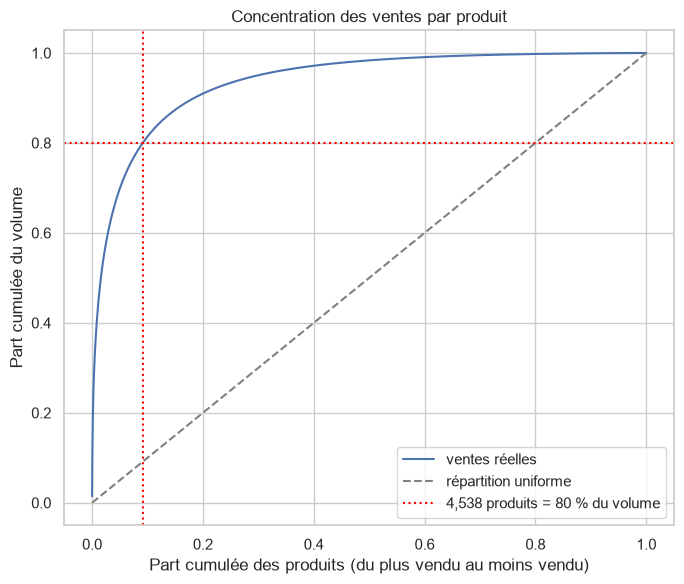

In [24]:
plt.figure(figsize=(7, 6))
plt.plot(cumul_produits, cumul_volume, label="ventes réelles")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="répartition uniforme")
plt.axvline(k80 / len(ventes), color="red", linestyle=":")
plt.axhline(0.8, color="red", linestyle=":", label=f"{k80:,} produits = 80 % du volume")

plt.xlabel("Part cumulée des produits (du plus vendu au moins vendu)")
plt.ylabel("Part cumulée du volume")
plt.title("Concentration des ventes par produit")
plt.legend()
plt.tight_layout()
plt.show()


**Observations :**

- La courbe monte très vite puis s'aplatit : **~9 % des produits font 80 % du
  volume**, ~18 % en font 90 %. La concentration est plus forte que le 80/20
  habituel.
- Le 1 % de tête (~500 produits) pèse ~43 % des ventes.
- À l'autre bout, 131 produits n'ont été achetés qu'une fois et 11 jamais : une
  longue traîne sans effet sur le volume.

**Piste business :**

L'activité repose sur un noyau de quelques milliers de références : priorité sur leur
disponibilité et leur prix. La longue traîne peut être rationalisée (stock,
référencement) sans impact sur le volume ; vérifier au préalable son rôle éventuel
sur la complétude perçue de l'offre.
